In [12]:
import os
import shutil
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Locate and copy script_rag.py to current working directory
# Adjust the search path if you put it inside a specific folder (e.g., 'Colab Notebooks')
source_path = '/content/drive/MyDrive/script_rag.py'
destination_path = '/content/script_rag.py'

if os.path.exists(source_path):
    shutil.copy(source_path, destination_path)
    print("Successfully copied script_rag.py from Drive to current workspace!")
else:
    # Fallback search if it is located in a subdirectory
    found = False
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'script_rag.py' in files:
            shutil.copy(os.path.join(root, 'script_rag.py'), destination_path)
            print(f"Successfully found and copied script_rag.py from: {root}")
            found = True
            break
    if not found:
        print("Could not find 'script_rag.py' in your Google Drive root. Please verify its location in Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully copied script_rag.py from Drive to current workspace!


In [13]:
"""
K-Means x Ridge-Logistic-Regression matching engine
90 days of UPI-derived features  ->  segment + calibrated score band + safe offer list
                                  ->  script_rag.py (plain-English script)

!! DATA IS SYNTHETIC. Replace `make_synthetic_data()` with the features from your two
   notebooks (keep the column names, or edit FEATURES / REASON_TEXT below).

Design in one line:  RULES decide what is ALLOWED, LOGISTIC REGRESSION says how RISKY,
                     K-MEANS says what KIND of earner, a POLICY MATRIX picks the action.
"""
import numpy as np, pandas as pd
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ── 1. features (90-day UPI window) ─────────────────────────────────────────
FEATURES = ["active_days_ratio", "avg_daily_inflow", "inflow_cv", "payer_diversity",
            "bill_on_time_ratio", "low_balance_days_ratio", "essential_spend_share"]
CLUSTER_FEATURES = ["active_days_ratio", "avg_daily_inflow", "inflow_cv", "payer_diversity"]
REASON_TEXT = {   # (text when it HELPS, text when it HURTS)
    "active_days_ratio":      ("you earn on most days", "you earn on few days"),
    "avg_daily_inflow":       ("your daily income is steady", "your daily income is low"),
    "inflow_cv":              ("your income does not swing much", "your income swings a lot"),
    "payer_diversity":        ("money comes from many sources", "money comes from few sources"),
    "bill_on_time_ratio":     ("you pay bills on time", "some bills were paid late"),
    "low_balance_days_ratio": ("your balance rarely hits zero", "your balance often hits zero"),
    "essential_spend_share":  ("food, rent and bills leave some room", "food, rent and bills use most of your money"),
}

def make_synthetic_data(n=3000, seed=7):
    r = np.random.default_rng(seed)
    kind = r.choice(3, n, p=[.40, .35, .25])                  # hidden worker types
    active = np.clip(r.normal(np.choose(kind, [.85, .50, .70]), .08), .1, 1)
    inflow = np.clip(r.normal(np.choose(kind, [650, 380, 480]), 110), 120, None)
    cv = np.clip(r.normal(np.choose(kind, [.35, .95, .60]), .15), .1, 2)
    payers = np.clip(r.normal(np.choose(kind, [7, 3, 12]), 2).round(), 1, None)
    ontime = np.clip(r.normal(np.choose(kind, [.90, .65, .80]), .10), 0, 1)
    lowbal = np.clip(r.normal(np.choose(kind, [.10, .40, .22]), .08), 0, 1)
    ess = np.clip(r.normal(np.choose(kind, [.55, .78, .66]), .08), .2, 1)
    df = pd.DataFrame(dict(active_days_ratio=active, avg_daily_inflow=inflow, inflow_cv=cv,
                           payer_diversity=payers, bill_on_time_ratio=ontime,
                           low_balance_days_ratio=lowbal, essential_spend_share=ess))
    z = (2.2*(active-.65) + 0.004*(inflow-480) - 1.6*(cv-.6) + 0.05*(payers-6)
         + 2.5*(ontime-.75) - 3.0*(lowbal-.2) - 2.0*(ess-.65))
    df["repaid"] = (r.random(n) < 1/(1+np.exp(-(z + .3)))).astype(int)   # synthetic label
    return df

# ── 2. models ────────────────────────────────────────────────────────────────
class Engine:
    BANDS = [(0.45, "A"), (0.62, "B"), (0.78, "C"), (1.01, "D")]   # POLICY PARAMETERS

    def fit(self, df, k=3, C=0.5):
        tr, te = train_test_split(df, test_size=.25, random_state=1, stratify=df["repaid"])
        # K-Means: behaviour only (no outcome label, no credit data)
        self.cs = StandardScaler().fit(tr[CLUSTER_FEATURES])
        self.km = KMeans(k, n_init=10, random_state=1).fit(self.cs.transform(tr[CLUSTER_FEATURES]))
        self.names = self._name_clusters(tr)
        # Ridge logistic regression (sklearn default penalty is L2): repayment probability
        self.ls = StandardScaler().fit(tr[FEATURES])
        self.lr = LogisticRegression(C=C, max_iter=1000).fit(self.ls.transform(tr[FEATURES]), tr["repaid"])
        p = self.lr.predict_proba(self.ls.transform(te[FEATURES]))[:, 1]
        self.metrics = {"AUC": round(roc_auc_score(te["repaid"], p), 3),
                        "Brier": round(brier_score_loss(te["repaid"], p), 3)}
        self.test = te.assign(p=p, segment=[self.segment(r) for _, r in te.iterrows()])
        return self

    def _name_clusters(self, df):
        lab = self.km.predict(self.cs.transform(df[CLUSTER_FEATURES]))
        g = df.assign(c=lab).groupby("c")[CLUSTER_FEATURES].mean()
        names = {}
        for c, row in g.iterrows():
            if row.active_days_ratio > .75 and row.inflow_cv < .5: names[c] = "Steady daily earner"
            elif row.inflow_cv > .8:                                names[c] = "Irregular earner"
            else:                                                   names[c] = "Mixed-source earner"
        return names

    def segment(self, row):
        c = self.km.predict(self.cs.transform(pd.DataFrame([row[CLUSTER_FEATURES]])))[0]
        return self.names[c]

    def score(self, row):
        x = self.ls.transform(pd.DataFrame([row[FEATURES]]))
        p = float(self.lr.predict_proba(x)[0, 1])
        contrib = self.lr.coef_[0] * x[0]                     # signed, in log-odds
        order = np.argsort(contrib)
        helps = [FEATURES[i] for i in order[::-1][:2] if contrib[i] > 0]
        hurts = [FEATURES[i] for i in order[:2] if contrib[i] < 0]
        return p, [REASON_TEXT[f][0] for f in helps], [REASON_TEXT[f][1] for f in hurts]

# ── 3. policy: rules -> band -> matrix ──────────────────────────────────────
# credit_ok = may we even mention credit?   Irregular earners get insurance/savings
# first even at a good band: repayment timing, not just probability, is the risk.
POLICY = {   # (segment, band) -> (max band allowed for credit, product kinds to lead with)
    "Steady daily earner": {"A": (False, ["enrolment", "insurance"]),
                            "B": (True,  ["loan", "insurance"]),
                            "C": (True,  ["loan", "savings", "insurance"]),
                            "D": (True,  ["loan", "savings", "insurance"])},
    "Mixed-source earner": {"A": (False, ["enrolment", "insurance"]),
                            "B": (False, ["insurance", "savings"]),
                            "C": (True,  ["loan", "savings", "insurance"]),
                            "D": (True,  ["loan", "savings", "insurance"])},
    "Irregular earner":    {"A": (False, ["enrolment", "insurance"]),
                            "B": (False, ["insurance", "savings"]),
                            "C": (False, ["savings", "insurance"]),
                            "D": (True,  ["loan", "savings", "insurance"])},
}
MIN_REPAY_SHARE = 0.20      # of monthly inflow - POLICY PARAMETER, set with credit risk

def decide(engine, row, occupation, has_bank_account, consent=True, days_of_data=90):
    # hard rules FIRST - a model score can never override these
    if not consent:
        return {"blocked": "No consent to use UPI data - no scoring."}
    if days_of_data < 60:
        return {"blocked": "Less than 60 days of data - too thin to score. Offer e-Shram sign-up only."}
    p, helps, hurts = engine.score(row)
    seg = engine.segment(row)
    band = next(b for cut, b in engine.BANDS if p < cut)
    credit_ok, kinds = POLICY[seg][band]
    if not has_bank_account:                               # most schemes need an account
        credit_ok = False
        kinds = list(dict.fromkeys(["enrolment"] + [k for k in kinds if k != "loan"]))
    monthly_inflow = row["avg_daily_inflow"] * 30 * row["active_days_ratio"]
    return {"segment": seg, "p_repay": round(p, 2), "band": band, "tier": band,
            "credit_ok": credit_ok, "lead_with": kinds,
            "max_monthly_repayment": round(MIN_REPAY_SHARE * monthly_inflow * (1 - min(row["inflow_cv"], 1) * .5)) if credit_ok else 0,
            "reasons": helps + (hurts if band in ("A", "B") else []),   # no negatives for strong scores
            "occupation": occupation, "has_bank_account": has_bank_account}

# ── 4. governance audit (what a model-risk reviewer will ask for first) ─────
def audit(engine):
    t = engine.test.copy()
    t["band"] = [next(b for cut, b in engine.BANDS if p < cut) for p in t["p"]]
    print("\nAUDIT 1 - performance by segment (large gaps = model works worse for a group)")
    for s, g in t.groupby("segment"):
        auc = roc_auc_score(g["repaid"], g["p"]) if g["repaid"].nunique() > 1 else float("nan")
        print(f"  {s:<22} n={len(g):>4}  AUC={auc:.3f}  actual repay rate={g['repaid'].mean():.2f}  mean score={g['p'].mean():.2f}")
    print("\nAUDIT 2 - calibration by band (mean predicted vs actual repayment)")
    for b, g in t.groupby("band"):
        print(f"  band {b}: n={len(g):>4}  predicted={g['p'].mean():.2f}  actual={g['repaid'].mean():.2f}")
    print("\nAUDIT 3 - share of each segment that is allowed credit messaging")
    t["credit"] = [POLICY[s][b][0] for s, b in zip(t["segment"], t["band"])]
    print(t.groupby("segment")["credit"].mean().round(2).to_string())

# ── 5. demo: end-to-end into the script optimiser ───────────────────────────
if __name__ == "__main__":
    df = make_synthetic_data()
    eng = Engine().fit(df)
    print("Hold-out metrics:", eng.metrics)
    print("Ridge coefficients (standardised):",
          dict(zip(FEATURES, eng.lr.coef_[0].round(2))))
    audit(eng)

    try:
        from script_rag import SchemeRetriever, KB, optimise
        retriever = SchemeRetriever(KB)
        workers = [
            ("Delivery rider, steady",   df[df.active_days_ratio > .85].iloc[0], "delivery rider", True),
            ("Ride driver, no account",  df[df.inflow_cv > 1.0].iloc[0],         "ride-app driver", False),
            ("Street vendor, mixed",     df[(df.payer_diversity > 11)].iloc[0],  "street vendor",  True),
        ]
        for label, row, occ, bank in workers:
            d = decide(eng, row, occ, bank)
            print("\n" + "=" * 78 + f"\n{label}")
            print({k: v for k, v in d.items() if k not in ("occupation", "has_bank_account")})
            res = optimise(d, retriever)
            print("Offers retrieved:", [f["id"] for f in res.facts])
            print("Script:", res.script)
            last = [h for h in res.history if "grade" in h][-1]
            print(f"readability grade {last['grade']} | safe_to_ship={res.safe_to_ship}")
    except ModuleNotFoundError:
        print("\n" + "!" * 78)
        print("NOTICE: 'script_rag' module was not found. Please upload or create 'script_rag.py'")
        print("to view the fully generated RAG offers and dynamic scripts.")
        print("!" * 78)


Hold-out metrics: {'AUC': np.float64(0.907), 'Brier': np.float64(0.112)}
Ridge coefficients (standardised): {'active_days_ratio': np.float64(0.34), 'avg_daily_inflow': np.float64(0.55), 'inflow_cv': np.float64(-0.6), 'payer_diversity': np.float64(0.08), 'bill_on_time_ratio': np.float64(0.33), 'low_balance_days_ratio': np.float64(-0.4), 'essential_spend_share': np.float64(-0.28)}

AUDIT 1 - performance by segment (large gaps = model works worse for a group)
  Irregular earner       n= 252  AUC=0.520  actual repay rate=0.08  mean score=0.12
  Mixed-source earner    n= 208  AUC=0.626  actual repay rate=0.69  mean score=0.65
  Steady daily earner    n= 290  AUC=0.656  actual repay rate=0.91  mean score=0.92

AUDIT 2 - calibration by band (mean predicted vs actual repayment)
  band A: n= 273  predicted=0.14  actual=0.11
  band B: n=  68  predicted=0.55  actual=0.62
  band C: n=  85  predicted=0.70  actual=0.69
  band D: n= 324  predicted=0.92  actual=0.91

AUDIT 3 - share of each segment th

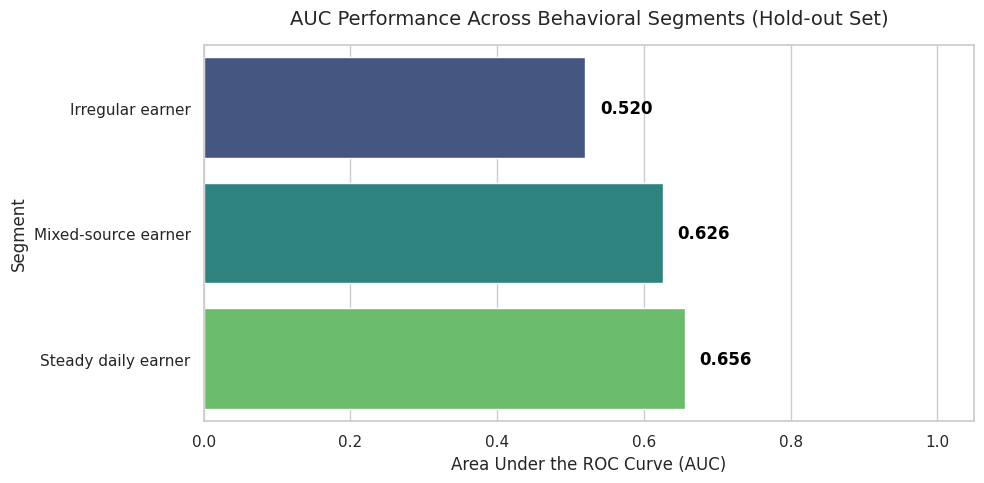

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

# Extract test predictions from our trained engine
test_df = eng.test.copy()

# Calculate AUC for each segment
segment_auc = {}
for segment_name, group in test_df.groupby("segment"):
    if group["repaid"].nunique() > 1:
        auc_val = roc_auc_score(group["repaid"], group["p"])
        segment_auc[segment_name] = auc_val
    else:
        segment_auc[segment_name] = np.nan

# Convert to a DataFrame for plotting
auc_df = pd.DataFrame(list(segment_auc.items()), columns=["Segment", "AUC"]).dropna()

# Create the plot
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x="AUC",
    y="Segment",
    data=auc_df,
    palette="viridis",
    hue="Segment",
    legend=False
)

# Customize plot features
plt.title("AUC Performance Across Behavioral Segments (Hold-out Set)", fontsize=14, pad=15)
plt.xlabel("Area Under the ROC Curve (AUC)", fontsize=12)
plt.ylabel("Segment", fontsize=12)
plt.xlim(0, 1.05)

# Annotate the exact bar values
for index, row in auc_df.iterrows():
    ax.text(
        row["AUC"] + 0.02,
        index,
        f"{row['AUC']:.3f}",
        color='black',
        ha="left",
        va="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

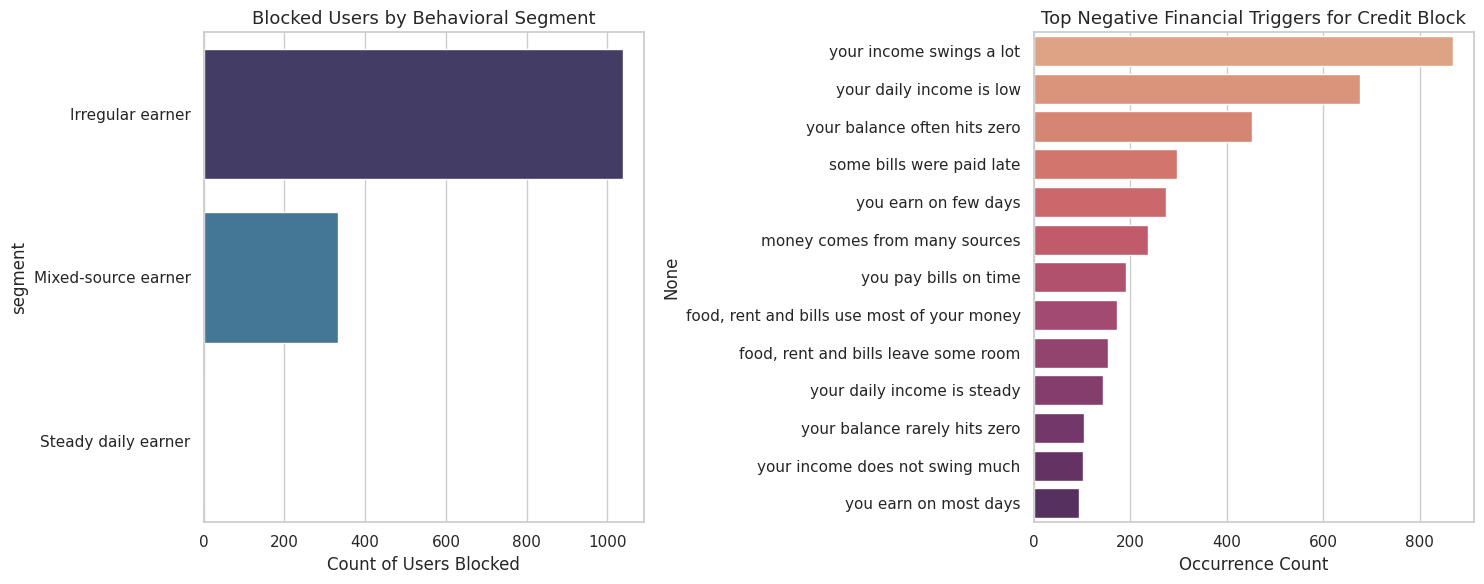

Total users analyzed: 3000
Total users blocked from credit: 1373 (45.8%)


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Run our simulated dataset through the decision engine
decisions = []
for idx, row in df.iterrows():
    # Simulating occupation and account variables for demonstration
    decision = decide(eng, row, occupation="gig_worker", has_bank_account=True, consent=True, days_of_data=90)
    decision["user_id"] = idx
    decisions.append(decision)

decisions_df = pd.DataFrame(decisions)

# 2. Filter out users who are blocked from credit (credit_ok == False)
blocked_users = decisions_df[decisions_df["credit_ok"] == False].copy()

# 3. Analyze the breakdown of segments among blocked users
blocked_segment_counts = blocked_users["segment"].value_counts()

# 4. Extract and analyze the primary reasons for blocking
reasons_list = []
for r_list in blocked_users["reasons"]:
    if isinstance(r_list, list):
        reasons_list.extend(r_list)

reasons_series = pd.Series(reasons_list)
blocked_reasons_counts = reasons_series.value_counts()

# 5. Visualize the results
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    x=blocked_segment_counts.values,
    y=blocked_segment_counts.index,
    ax=axes[0],
    palette="mako",
    hue=blocked_segment_counts.index,
    legend=False
)
axes[0].set_title("Blocked Users by Behavioral Segment", fontsize=13)
axes[0].set_xlabel("Count of Users Blocked")

sns.barplot(
    x=blocked_reasons_counts.values,
    y=blocked_reasons_counts.index,
    ax=axes[1],
    palette="flare",
    hue=blocked_reasons_counts.index,
    legend=False
)
axes[1].set_title("Top Negative Financial Triggers for Credit Block", fontsize=13)
axes[1].set_xlabel("Occurrence Count")

plt.tight_layout()
plt.show()

# Summary output
print(f"Total users analyzed: {len(decisions_df)}")
print(f"Total users blocked from credit: {len(blocked_users)} ({len(blocked_users)/len(decisions_df)*100:.1f}%)")